# RNA-only GRN evaluation: start with the big picture

**NCI60 · full expressed-gene networks · native GRETA tasks**

We compare a lightweight RNA-derived GRN with the full eligible CollecTRI prior and a random control. First obtain the overall heatmap; then ask what the Predictive, Literature and Mechanistic columns actually tell us.

This is an **RNA-only** practical using real cancer cell-line measurements. Genomic-region tasks and RNA+ATAC inference belong to the later session. See [README.md](README.md) for setup and [TASKS.md](TASKS.md) for the RNA-only interpretation guide.

Use the same Python 3.12 environment. Restart the kernel before running this revised notebook. The first full benchmark fits many prediction models and can take minutes; subsequent runs reuse results only if the inputs, settings, references, code and package versions still match.

In [1]:
from pathlib import Path
import os
import sys
import tempfile
import importlib

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-matplotlib"))
os.environ.setdefault("NUMBA_CACHE_DIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-numba"))
HERE = next((p for p in [Path.cwd(), Path.cwd() / "GRN_comparison"]
             if (p / "rna_benchmark.py").exists()), None)
if HERE is None:
    raise RuntimeError("Open from the repository root or GRN_comparison.")
sys.path.insert(0, str(HERE))

# Reload the revised helpers if using an already-open interactive kernel.
import greta_benchmark
importlib.reload(greta_benchmark)
import rna_benchmark
importlib.reload(rna_benchmark)

import gretapy as gt
import pandas as pd
from IPython.display import display
from rna_benchmark import RnaConfig, run_rna
print("gretapy", gt.__version__)

/Users/dugourd/Documents/COSMOS_basic/GRN_comparison/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gretapy 0.0.3


In [3]:
# Zero caps mean all genes/TFs passing the stated eligibility criteria.
config = RnaConfig(
    max_genes=0,
    max_tfs=0,
    include_spearman=False,
    profile="teaching",   # "quick" omits KnockTF, retaining the full networks
)
result = run_rna(config, output_dir=HERE / "results" / "rna", force=False)
res = result["res"]
print("Verified cache reused:", result["cache_hit"])

Loading RNA and selecting genes using training samples...
Reusing scores and figures from the verified matching cache.
Verified cache reused: True


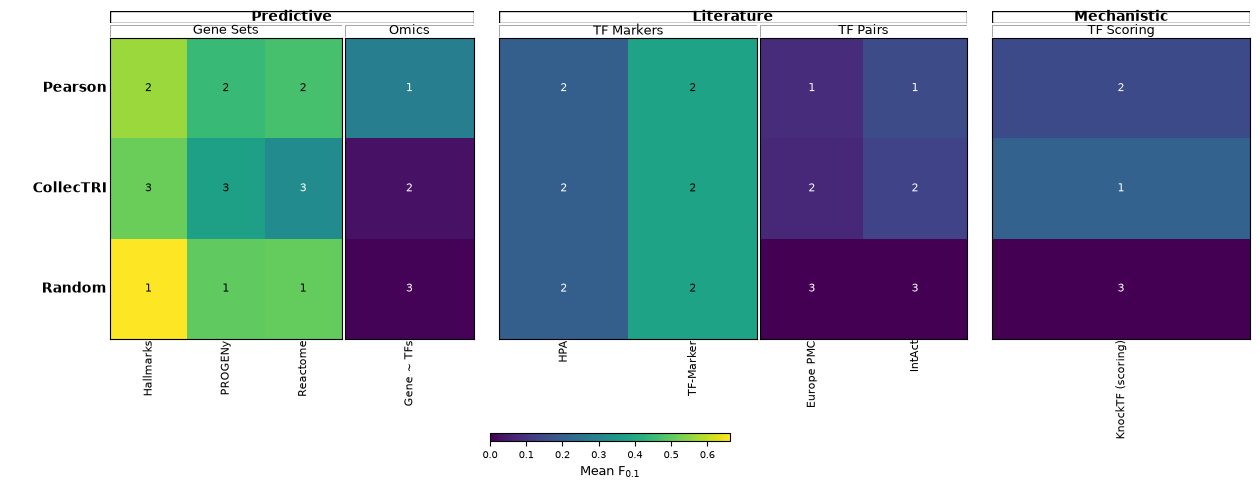

In [4]:
# Overall task heatmap FIRST: this is the main result to explain below.
gt.pl.ranking(res, level="task", figsize=(16, 5))

## Read the overall heatmap

Each row is a network. Columns are databases or subtasks, grouped into broader tasks and categories. Colors show F₀.₁ scores; numbers show ranks **within each column**, where 1 is best. Ties get average ranks. A rank is not a statistical significance test.

The ordering combines tasks within their categories, with equal default category weights. Only the **three RNA-applicable categories evaluated here** enter this comparison; an absent Genomic category is not a zero score.

Before deciding which network is preferable, identify the columns driving its position. A network may predict RNA variation well while performing less well on external TF-loss profiles.

**Calibration warning:** this figure reproduces native GRETA scores. TF Markers tie because all baselines share their TFs; Gene Sets can reward random wiring. The composite ordering is not an established ranking of GRN wiring quality. We examine these limitations below.

In [4]:
display(gt.tl.ranking(res))
print("Compared columns:", ", ".join(sorted(res.db.unique())))

,mean_f01,NCI60 RNA
name,,
Pearson,0.247547,0.247547
CollecTRI,0.207955,0.207955
Random,0.142556,0.142556


Compared columns: Europe PMC, Gene ~ TFs, HPA, Hallmarks, IntAct, KnockTF (scoring), PROGENy, Reactome, TF-Marker


## What went into that comparison?

The input is the uncensored CellMiner log₂(FPKM + 1) matrix already supplied in this repository: **23,808 genes across all 60 NCI60 cell lines**. The original column prefixes provide bulk tissue groups for stratification. GRETA stores them in a field named `celltype`; they are not single-cell identities.

The native stratified split gives **40 training and 20 test cell lines**. A gene is retained if expression is at least 1 in 80% of training samples and its training variance is nonzero. This leaves **7,530 genes**, without an arbitrary gene-number cap. Filtering and inferred edge selection do not use test expression.

All eligible native CollecTRI sources with at least three retained non-self targets are used: **195 regulators**. The complete eligible prior contains **6,871 edges**. It is not subsampled to make a tiny graph.

In [5]:
display(gt.tl.stats(result["networks"]))
display(result["split"].groupby("partition").size().rename("samples"))
print("RNA shape (samples × retained genes):", result["adata"].shape)

,name,n_sources,n_cres,n_targets,n_edges,mean_regulon_size
0,Pearson,195,0,4149,6871,35.235897
1,CollecTRI,195,0,2002,6871,35.235897
2,Random,195,0,4533,6871,35.235897


partition
test     20
train    40
Name: samples, dtype: int64

RNA shape (samples × retained genes): (60, 7530)


### A short explanation of the inferred GRN

For each regulator, Pearson correlation asks which candidate genes have RNA abundance that varies with its own RNA abundance **across training cell lines**. The strongest absolute correlations become directed TF→target associations. Direction comes from designating the source as a regulator; correlation itself is symmetric.

We calculate the TF-by-gene correlations efficiently, rather than building a large gene-by-gene matrix. Every retained gene is a candidate target. To control network complexity, each regulator gets the same number of outgoing edges it has in the complete eligible CollecTRI prior. CollecTRI therefore supplies the regulator list and degree budget, while expression selects the inferred target identities.

The random control samples the same number of non-self targets per regulator and assigns random signs. These are null-model signs, not regulatory evidence. Equal outgoing degrees do not equalize target coverage, incoming degrees or sign distributions.

Pearson is a fast baseline, not a claim to reconstruct a complete causal GRN. TF RNA need not reflect TF activity, and shared tissue programs can create indirect correlations. Optional Spearman inference uses ranks instead of expression magnitudes.

In [6]:
display(result["networks"]["Pearson"].head(10))
budgets = pd.DataFrame({name: net.groupby("source").size()
                        for name, net in result["networks"].items()})
assert budgets.nunique(axis=1).eq(1).all()
print(f"Matched degrees for {len(budgets)} regulators; "
      f"{int(budgets.iloc[:, 0].sum()):,} edges per network.")

,source,target,score
0,AHR,EPS8,0.715474
1,AHR,SKAP2,0.714382
2,AHR,LAMB1,0.699907
3,AHR,FKBP9,0.699483
4,AHR,PERP,0.671660
5,AHR,NPTN,0.671636
6,AHR,BAIAP2L1,0.670425
7,AHR,DHX32,0.669001
8,AHR,DPY19L1,0.653874
9,AHR,NCEH1,0.653337


Matched degrees for 195 regulators; 6,871 edges per network.


## 1. Predictive: does the network select useful predictors and functions?

There are two tasks in this category:

- **Omics — Gene ~ TFs:** fit a common prediction model using each target's incoming TF RNA, then test whether predicted and observed RNA values correlate in held-out cell lines. This tests predictive topology; it does not count experimentally correct regulatory edges.
- **Gene Sets — Hallmarks, PROGENy, Reactome:** compare RNA-enriched pathway labels with pathway labels enriched among TF target sets. The Hallmarks example below explains how the two lists are built. A high F₀.₁ does not necessarily mean broad pathway recovery or accurate TF–target wiring.

The following panel expands the Predictive columns from the overview. Separate panels can have different color scales and row orderings: follow method names and colorbars.

,name,task,db,precision,recall,f01
6,Pearson,Omics,Gene ~ TFs,0.284888,0.156972,0.282608
7,CollecTRI,Omics,Gene ~ TFs,0.033467,0.008898,0.032576
8,Random,Omics,Gene ~ TFs,0.006618,0.003984,0.006575
15,Pearson,Gene Sets,Hallmarks,0.562500,0.750000,0.563896
16,CollecTRI,Gene Sets,Hallmarks,0.510638,1.000000,0.513124
17,Random,Gene Sets,Hallmarks,0.666667,0.416667,0.662730
18,Pearson,Gene Sets,PROGENy,0.444444,1.000000,0.446903
19,CollecTRI,Gene Sets,PROGENy,0.375000,0.750000,0.376866
20,Random,Gene Sets,PROGENy,0.500000,0.500000,0.500000
24,Pearson,Gene Sets,Reactome,0.469816,0.445274,0.469560


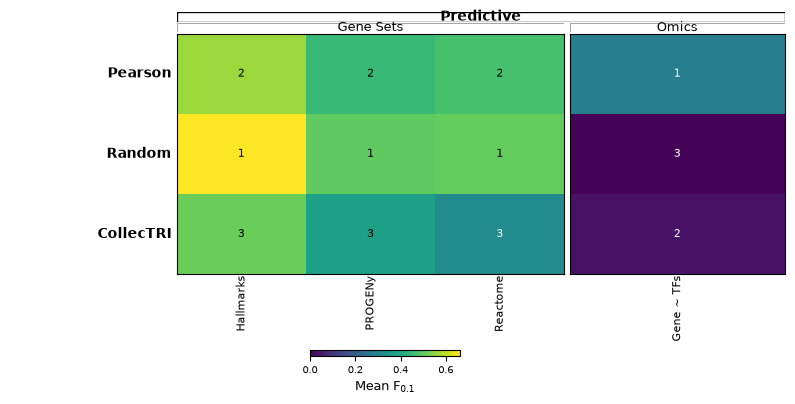

In [7]:
predictive = res[res["class"].eq("Predictive")]
gt.pl.ranking(predictive, level="task", figsize=(10, 4))
display(predictive[["name", "task", "db", "precision", "recall", "f01"]])

### Gene Sets: compare two lists of pathway names

**Question: do pathways whose genes are relatively highly expressed also appear as enriched labels somewhere among the TF target sets?**

GRETA builds two lists separately. For our unweighted **Hallmarks** pathways:

1. **RNA → List A.** In each cell line, ULM asks whether a pathway's genes have higher average log-expression than other measured genes. A pathway enters List A when its score is positive with adjusted p < 0.01 in **more than 20% of lines** (at least 13/60). This uses all 60 lines and gives **24 RNA-enriched pathways**. It describes relative expression within a cell line; it does not establish activation against a control condition.
2. **TF target sets → List B.** For each TF, test whether its targets contain more pathway genes than expected by chance (Fisher enrichment, adjusted p < 0.01). Pool pathways passing for **any TF**. Ignore GRN edge signs and strengths, and count each pathway once. Pearson supports **32 pathways** this way.
3. **Compare the names.** A pathway in both lists is a **TP**; in List B only, an **FP**; in List A only, an **FN**. These are agreement labels, not verified biological positives/negatives.

**Coagulation in our data:** it is RNA-enriched in **30/60 lines**, so it enters List A. CollecTRI's HIF1A regulon contains **6 Coagulation genes among 190 targets** (native enrichment q = **0.00324**), so it also enters CollecTRI's List B: a TP. No Pearson regulon passes for this pathway, making it a Pearson FN.

Across all pathways, Pearson shares **18** names between its two lists: precision = **18/32**, recall = **18/24**, and F₀.₁ ≈ **0.564**.

The figure shows illustrative pathway rows; counts use all 50 Hallmarks. Its native 20,000-gene background, pooling across TFs, and precision-heavy F₀.₁ need calibration against random controls (see [TASKS.md](TASKS.md)). The score summarizes functional concordance, rather than identifying which TF correctly controls a pathway.

**Discuss:** find a TP, FP and FN in the figure. Why can Random have higher precision while recovering fewer RNA-enriched pathways?

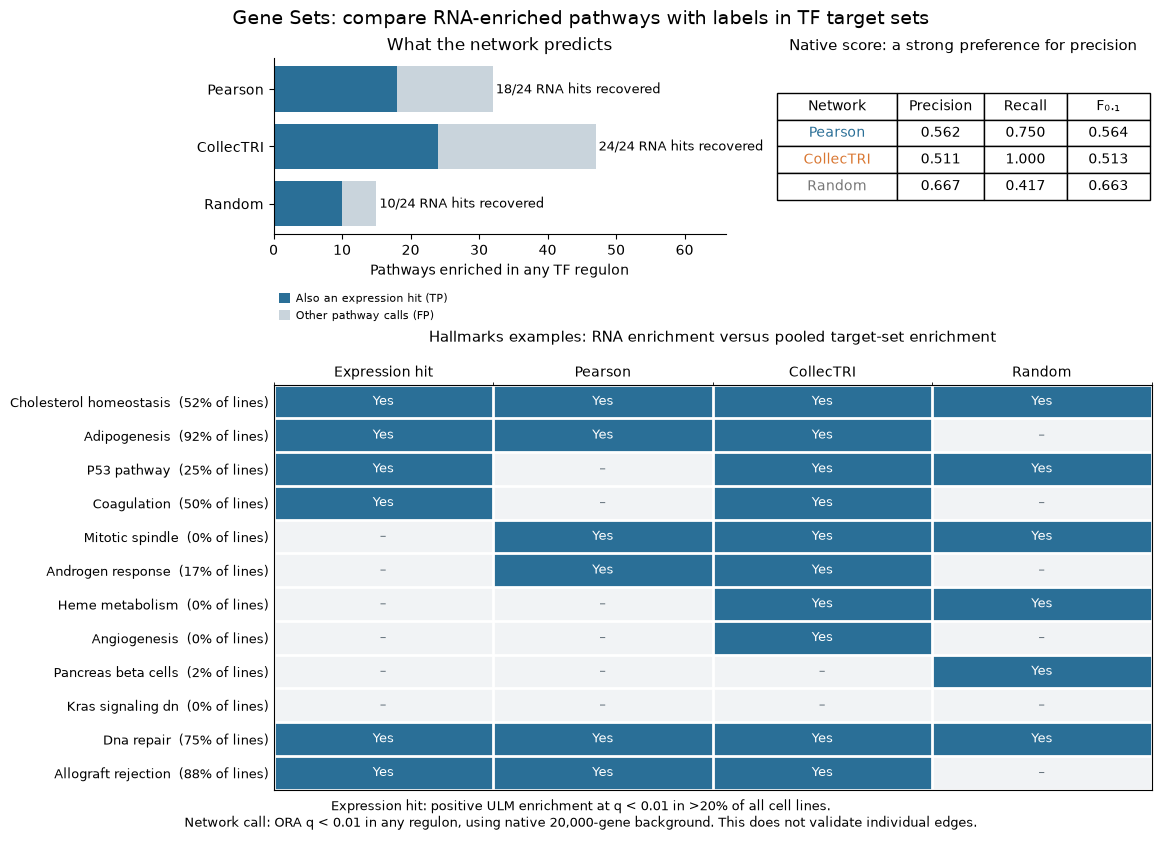

,name,n_predicted,n_expression_hits,tp,fp,fn,precision,recall,f01,counted_unit
0,Pearson,32,24,18,14,6,0.562500,0.750000,0.563896,Hallmark pathways
1,CollecTRI,47,24,24,23,0,0.510638,1.000000,0.513124,Hallmark pathways
2,Random,15,24,10,5,14,0.666667,0.416667,0.662730,Hallmark pathways


In [8]:
import matplotlib.pyplot as plt
from task_examples import (
    plot_gene_sets_example, plot_omics_example,
    plot_marker_example, plot_tf_pair_example, plot_knocktf_example,
    save_example,
)

gene_set_fig, gene_set_tables = plot_gene_sets_example(result)
display(gene_set_fig)
plt.close(gene_set_fig)
display(gene_set_tables["summary"])
example_dir = save_example(result, "gene_sets", gene_set_fig, gene_set_tables)

### Interpret prediction with coverage

Native Omics uses up to five incoming predictors per target, fits XGBoost on training observations, and counts targets whose held-out Spearman correlation is positive and significant after multiple-testing correction. Precision is successful / tested targets; recall is successful / all retained measured genes. CollecTRI’s signed weights generally do not rank confidence, so tied incoming edges are resolved by the native implementation’s ordering; correlation strengths provide a different predictor ordering.

A network can have high precision while covering fewer genes. CollecTRI and Pearson have the same number of edges here, but can distribute them across different targets. Inspect those differences before interpreting the heatmap.

The source RNA has no missing entries and this practical imputes nothing. **Native GRETA excludes zero-valued target responses**, although zero is a genuine possible measurement in this dataset; the prediction scores are conditional on those usable responses. Undefined constant-response correlations are excluded and counted.

In [9]:
coverage = result["coverage"]
display(coverage[coverage.db.eq("Gene ~ TFs")])

,name,db,status,n_tested,n_hits,n_skipped_constant_response,n_eligible,n_skipped_insufficient_targets
2,Pearson,Gene ~ TFs,evaluated,4149.0,1182.0,0.0,NaN,NaN
12,CollecTRI,Gene ~ TFs,evaluated,2002.0,67.0,0.0,NaN,NaN
22,Random,Gene ~ TFs,evaluated,4533.0,30.0,0.0,NaN,NaN


### See Omics prediction for one real target gene

Each point below is a **held-out NCI60 cell line**. The horizontal coordinate is observed target RNA; the vertical coordinate is the prediction from that network's incoming TFs. The dashed identity line represents perfect prediction, and tissue colors help reveal whether apparent predictability follows tissue differences.

The default gene is selected by its strongest **training-only** TF correlation among targets covered by all networks. The table records that rule and the actual TF predictors used. This intentionally illustrates a strong training association in Pearson; its test scatter is not an unbiased sample of method performance and does not summarize all genes. The displayed Spearman correlations are descriptive: a one-gene plot does not reproduce the benchmark's multiple-testing decision.

**Discuss:** are predictions close to the identity line, merely ordered correctly, or grouped by tissue? Why can a useful correlation remain insufficient evidence for a direct TF→target effect?

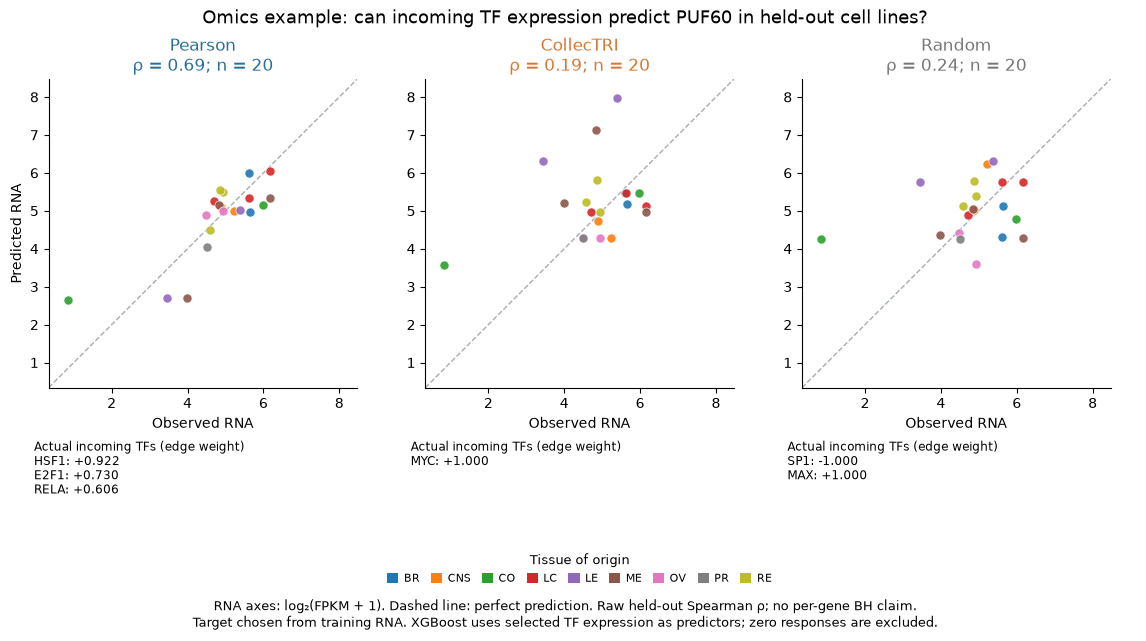

,target,automatically_selected,selection_rule,selection_network,n_candidate_targets,n_train_before_zero_filter,n_test_before_zero_filter,model,note
0,PUF60,True,Greatest absolute training TF–target correlati...,Pearson,684,40,20,"XGBRegressor(random_state=0, n_jobs=1)","Edge weights select up to five incoming TFs, b..."


,name,target,rank,source,score
0,Pearson,PUF60,1,HSF1,0.921845
1,Pearson,PUF60,2,E2F1,0.730177
2,Pearson,PUF60,3,RELA,0.605820
3,CollecTRI,PUF60,1,MYC,1.000000
4,Random,PUF60,1,SP1,-1.000000
5,Random,PUF60,2,MAX,1.000000


In [10]:
omics_fig, omics_tables = plot_omics_example(result)
# To inspect another covered gene, pass target="GENE_SYMBOL".
display(omics_fig)
plt.close(omics_fig)
display(omics_tables["selection"])
display(omics_tables["predictors"])
example_dir = save_example(result, "omics", omics_fig, omics_tables)

## 2. Literature: what previously reported biology does the network recover?

- **TF Markers — HPA and TF-Marker:** check regulator identities against marker collections. This does not inspect target wiring. Our matched regulator lists tie by construction. Keep these as regulator-selection diagnostics; they do not assess differences in wiring.
- **TF Pairs — IntAct and Europe PMC:** infer TF associations from unusually overlapping target sets, then compare these pairs with reported TF relationships. This is not simply a test of directed TF→TF edges.

These references are incomplete, unevenly studied and can share underlying publications. Here NCI60 is a mixture of tumor types, so the default uses broad reference collections rather than PBMC filtering or a single tissue's marker list. It is a broad annotation screen, not tissue-specific validation.

,name,task,db,precision,recall,f01
0,Pearson,TF Pairs,IntAct,0.157895,0.055556,0.155067
1,CollecTRI,TF Pairs,IntAct,0.131313,0.481481,0.132266
2,Random,TF Pairs,IntAct,0.000000,0.000000,0.000000
3,Pearson,TF Pairs,Europe PMC,0.084337,0.035714,0.083216
4,CollecTRI,TF Pairs,Europe PMC,0.074651,0.464286,0.075277
5,Random,TF Pairs,Europe PMC,0.000000,0.000000,0.000000
9,Pearson,TF Markers,TF-Marker,0.384615,0.367647,0.384440
10,CollecTRI,TF Markers,TF-Marker,0.384615,0.367647,0.384440
11,Random,TF Markers,TF-Marker,0.384615,0.367647,0.384440
21,Pearson,TF Markers,HPA,0.200000,0.609375,0.201339


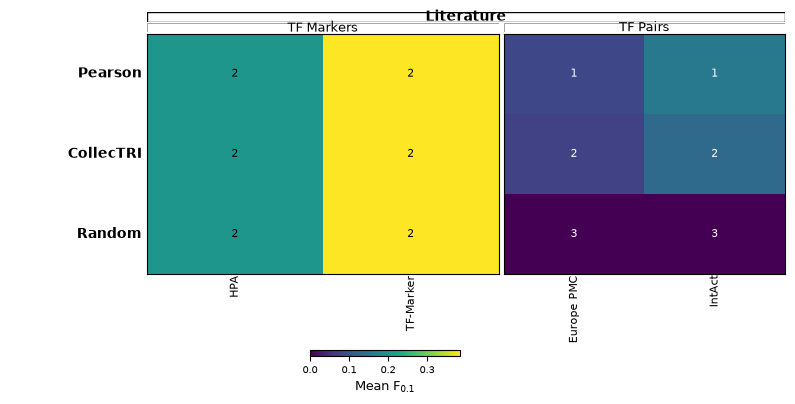

In [11]:
literature = res[res["class"].eq("Literature")]
gt.pl.ranking(literature, level="task", figsize=(10, 4))
display(literature[["name", "task", "db", "precision", "recall", "f01"]])

### See why TF Marker scores tie

These are the actual source TFs and reference memberships used in this run. The count panels separate TFs listed in a marker reference from TFs absent from it; the membership examples make the counted unit visible. Absence from a marker reference is not proof that a TF is biologically irrelevant.

**Discuss:** which entries could change if you rewired targets while retaining these TFs? The unchanged source identities explain why all three networks receive the same marker scores.

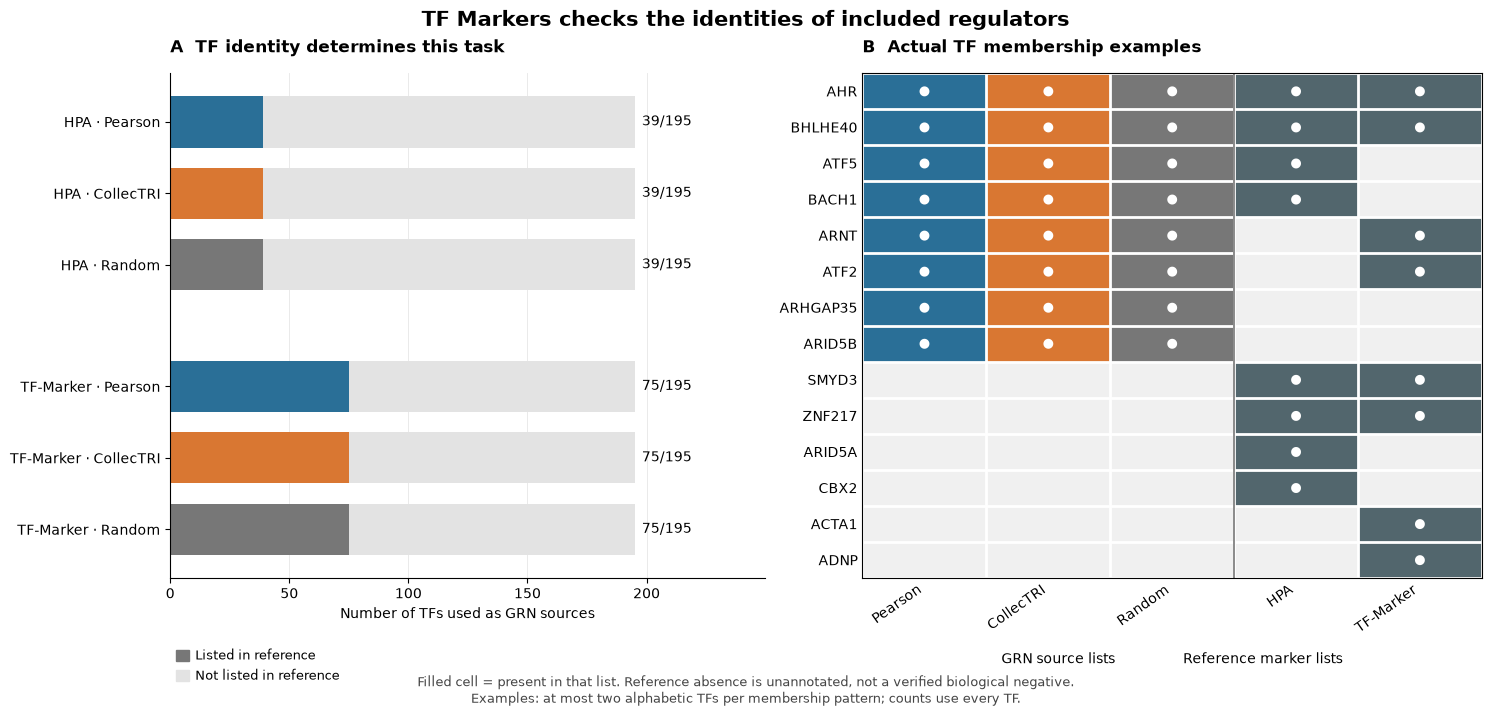

In [12]:
marker_fig, marker_tables = plot_marker_example(result)
display(marker_fig)
plt.close(marker_fig)
example_dir = save_example(result, "tf_markers", marker_fig, marker_tables)

### See TF Pairs as shared-target organization

The same pair of TFs is followed across the networks below. Target memberships show what “shared targets” means; the counts and enrichment results use the full target sets, even if only a subset of target names is drawn. The native enrichment background and correction over all eligible TF pairs are retained.

The default is an **illustrative reference-supported pair** with significant shared targets in at least one network. Its selection is reported alongside the plot; it is not a random sample of all pairs. A supported association does not establish a directed TF→TF regulatory edge.

**Discuss:** do the TFs merely have a large overlap, or a larger overlap than expected for their target-set sizes? What would a reported association without significant target sharing mean for this task?

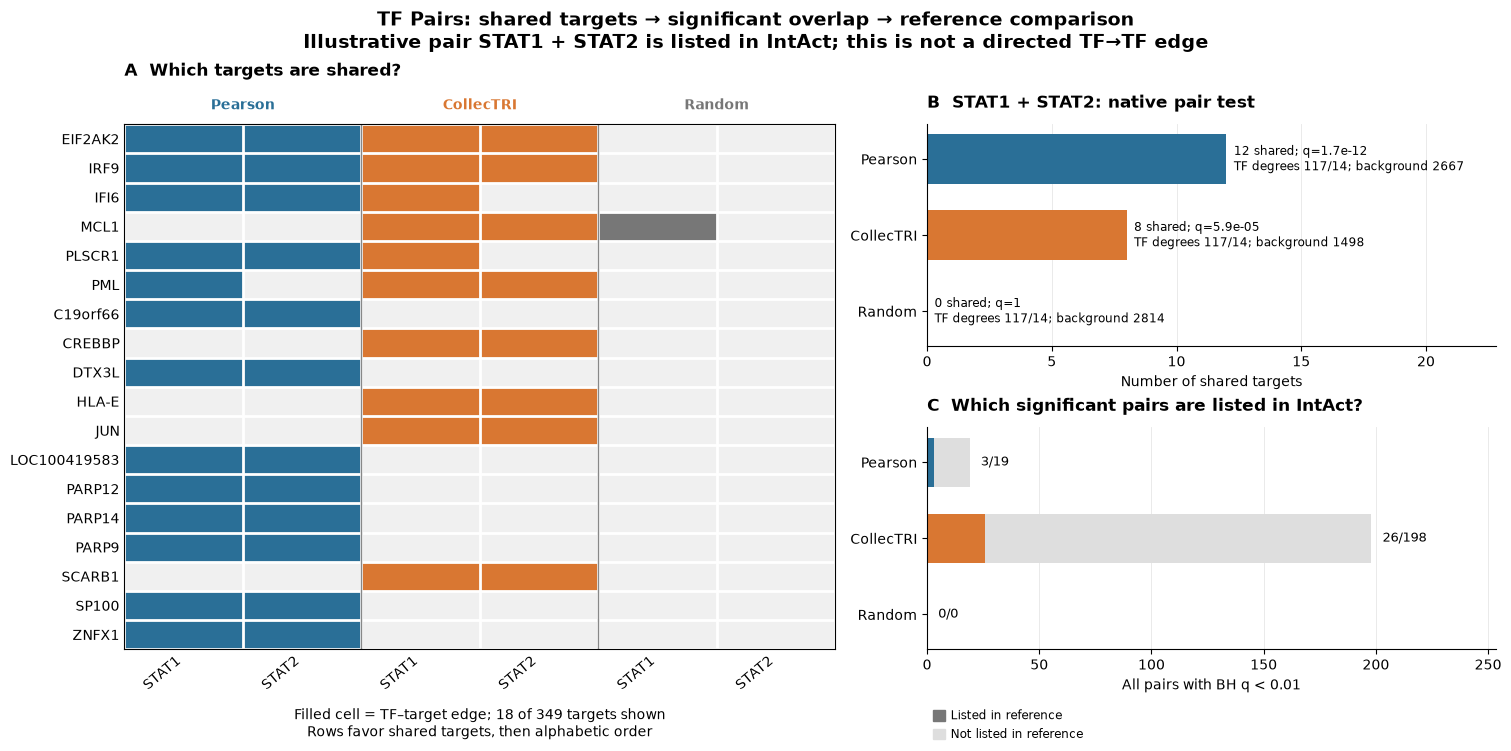

,network,tf_a,tf_b,targets_a,targets_b,shared_targets,background_targets,pval,padj,significant,in_reference,database,selection_rule
0,Pearson,STAT1,STAT2,117,14,12,2667,2.454838e-15,1.691383e-12,True,True,IntAct,Reference-supported pair with most significant...
1,CollecTRI,STAT1,STAT2,117,14,8,1498,2.217059e-06,5.875207e-05,True,True,IntAct,Reference-supported pair with most significant...
2,Random,STAT1,STAT2,117,14,0,2814,1.000000e+00,1.000000e+00,False,True,IntAct,Reference-supported pair with most significant...


In [13]:
pair_fig, pair_tables = plot_tf_pair_example(result)
# An explicit pair can be inspected with pair=("TF_A", "TF_B").
display(pair_fig)
plt.close(pair_fig)
display(pair_tables["selected_pair"])
example_dir = save_example(result, "tf_pairs", pair_fig, pair_tables)

### Keep self-reference separate

The additional **Reference GRN** task measures agreement with CollecTRI. It remains useful as a construction check and as a description of prior agreement. A CollecTRI-derived network compared with CollecTRI is circular, so this column is excluded from the overall ranking for every method.

An unlisted reference edge is not an established biological negative. A data-derived edge can disagree with a reference because it is indirect, context-dependent, erroneous, or simply unrecorded.

In [14]:
diagnostic = result["results"].query("db == 'CollecTRI'")
display(diagnostic[["name", "precision", "recall", "f01"]])
assert "CollecTRI" not in set(res.db)

,name,precision,recall,f01
4,Pearson,0.030563,0.029657,0.030554
14,CollecTRI,1.000000,0.970343,0.999697
24,Random,0.024014,0.023302,0.024007


## 3. Mechanistic: can a regulon detect a known TF perturbation?

**TF Scoring — KnockTF** uses external knockdown expression profiles. A network's signed targets estimate the perturbed regulator's activity; a successful test detects a significant activity decrease after TF loss.

This task can use RNA-only networks. It evaluates whether a regulon behaves usefully under this footprint model, not whether every edge is direct or causal. CollecTRI provides curated regulatory signs; Pearson provides association signs; random signs form a null. Those meanings differ.

The default uses the broad KnockTF collection for a mixed-tumor panel. Experiments can differ substantially in tissue or cell context. Inspect eligible experiments and target overlap, and choose explicit reference-term filters for a narrower biological question.

,name,task,db,precision,recall,f01
12,Pearson,TF Scoring,KnockTF (scoring),0.150000,0.076705,0.148594
13,CollecTRI,TF Scoring,KnockTF (scoring),0.209677,0.110795,0.207841
14,Random,TF Scoring,KnockTF (scoring),0.000000,0.000000,0.000000


,name,db,status,n_tested,n_hits,n_skipped_constant_response,n_eligible,n_skipped_insufficient_targets
5,Pearson,KnockTF (scoring),evaluated,180.0,27.0,NaN,352.0,9.0
15,CollecTRI,KnockTF (scoring),evaluated,186.0,39.0,NaN,352.0,3.0
25,Random,KnockTF (scoring),evaluated,186.0,0.0,NaN,352.0,3.0


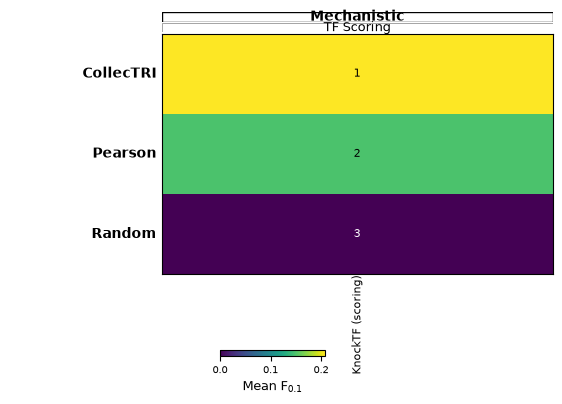

In [15]:
mechanistic = res[res["class"].eq("Mechanistic")]
if len(mechanistic):
    gt.pl.ranking(mechanistic, level="task", figsize=(7, 4))
    display(mechanistic[["name", "task", "db", "precision", "recall", "f01"]])
    display(coverage[coverage.db.eq("KnockTF (scoring)")])
else:
    print("KnockTF was omitted by the quick profile or lacked comparable usable evidence.")

### See TF loss through a real signed regulon

This example uses an **external KnockTF experiment**, not an NCI60 perturbation. The experiment metadata identifies the perturbed TF and its context. The default experiment is selected near the median measured TF knockdown among experiments testable with all three networks, independently of inferred activity.

Compare observed target responses with each network's signs, then examine the ULM activity estimate and adjusted p-value. For a positive regulatory edge, decreased target expression is consistent with TF loss; for a negative edge, increased target expression is consistent with TF loss. Pearson's signs are association signs, while CollecTRI's are curated regulatory signs.

The displayed adjusted p-values retain the native correction across supported perturbation experiments **within each network**, rather than correcting this single illustrative experiment alone. The plot illustrates the footprint; the full ULM calculation also uses the experiment's background genes.

**Discuss:** do target responses collectively support reduced activity? Distinguish an incorrect activity direction, a negative but nonsignificant score, and insufficient target coverage.

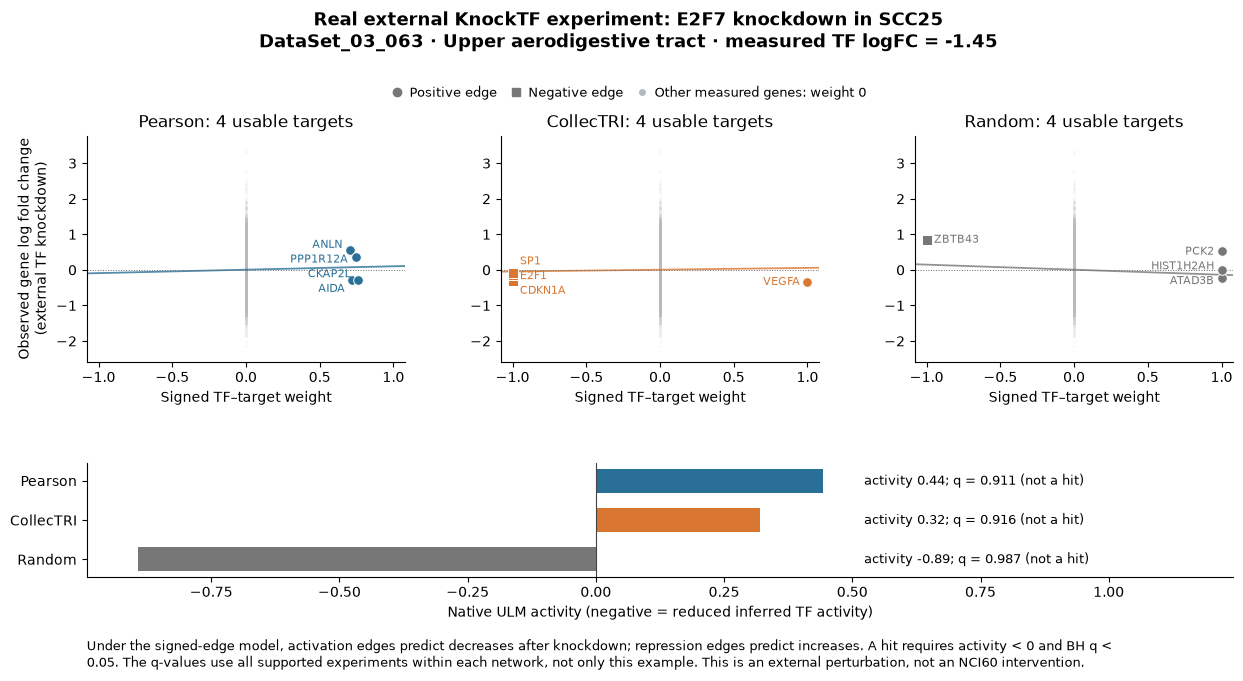

,0
experiment,DataSet_03_063
TF,E2F7
Species,Homo sapiens
Knock.Method,siRNA
Biosample.Name,SCC25
Profile.ID,GSE58074
Platform,GPL10558
TF.Class,Fork head / winged helix factors
TF.Superclass,Helix-turn-helix domains
Tissue.Type,Upper_aerodigestive_tract


,name,experiment,TF,activity,pval,padj,hit
0,Pearson,DataSet_03_063,E2F7,0.442954,0.657804,0.910805,False
1,CollecTRI,DataSet_03_063,E2F7,0.319322,0.749486,0.916335,False
2,Random,DataSet_03_063,E2F7,-0.892741,0.372007,0.987462,False


Example figures and their underlying tables: /Users/dugourd/Documents/COSMOS_basic/GRN_comparison/results/rna/examples


In [16]:
knocktf_fig, knocktf_tables = plot_knocktf_example(result)
# Pass experiment="EXPERIMENT_ID" to inspect a different eligible experiment.
display(knocktf_fig)
plt.close(knocktf_fig)
display(knocktf_tables["experiment"].T)
display(knocktf_tables["selected_activity"])
example_dir = save_example(result, "knocktf", knocktf_fig, knocktf_tables)
print("Example figures and their underlying tables:", example_dir)

A zero with usable experiments is a tested negative result. No usable experiments is missing evidence. A perturbation profile needs at least three regulon targets with nonzero measured responses for the native ULM model. The compatibility helper excludes unusable experiments, records coverage, and retains the original eligible-experiment denominator for recall.

Other RNA-compatible mechanistic models, such as perturbation forecasting and Boolean steady-state simulation, require additional assumptions and can be much more expensive. They are not run by this first tutorial.

## Revisit the overall ranking

GRETA combines precision and recall as

\[
F_{0.1}=\frac{1.01PR}{0.01P+R}.
\]

It strongly emphasizes precision. The counted units differ across tasks, so this is not a universal percentage of correct edges. The overall ordering averages databases within tasks, tasks within categories, then combines available categories with their chosen weights. In this native reproduction, constant TF Marker tasks dilute TF Pairs within Literature, and uncalibrated Gene Sets contribute to Predictive. An intended comparison of wiring should separate marker diagnostics and validate gene-set scores against repeated appropriate null networks before including them in an aggregate.

Missing columns are not replaced with zero. For our comparison, a column without usable scores for any method is excluded for all methods, while the complete results and coverage remain available. Different numbers of tested genes or perturbations can still matter within a shared column.

In [17]:
display(gt.tl.ranking(res))
# Prespecify weights from the intended biological use; do not tune them to select a winner.
display(gt.tl.ranking(res, metric_weights={
    "predictive": 1, "literature": 1, "mechanistic": 2,
}))
print("Saved tables and figures:", result["output_dir"])
print("Run timing:", result["timing"])

,mean_f01,NCI60 RNA
name,,
Pearson,0.247547,0.247547
CollecTRI,0.207955,0.207955
Random,0.142556,0.142556


,mean_f01,NCI60 RNA
name,,
Pearson,0.222808,0.222808
CollecTRI,0.207926,0.207926
Random,0.106917,0.106917


Saved tables and figures: /Users/dugourd/Documents/COSMOS_basic/GRN_comparison/results/rna
Run timing: {'cache_load_seconds': 0.968926832996658}


## Experiments and your own RNA-only GRN

1. Explain a method's overall position using its category panels. Which biological use would support that preference?
2. Explain why TF-marker ties are expected while prediction can differ.
3. Compare target coverage and tested-target counts despite identical outgoing degrees.
4. Set `include_spearman=True` to add a second lightweight inference baseline. This changes the cache fingerprint and requires a new evaluation.
5. For a smaller computation, set optional `max_genes` or `max_tfs`; record that the evaluation universe changed. The defaults impose neither cap. `profile="quick"` only omits KnockTF and still constructs the full networks.
6. Replace the RNA input with prepared nonnegative log-normalized `.h5ad` data and supply `source,target,score` tables via `grn_paths`. The [README](README.md) specifies group labels, feature matching, reference filters and inference-provenance requirements.

The helper supports manifest-checked result reuse. Use `force=True` to recompute a matching run. Reusing a cache never substitutes an unrelated published benchmark for this analysis. If a supplied GRN already used the test samples during inference, the prediction split does not retroactively protect its topology from that information.

### Later: RNA + ATAC

Region plausibility, TF binding at selected CREs, CRE–gene assignment and accessibility prediction need matched chromatin inputs. They are absent from this RNA-only heatmap. The previous [paired-data preview](03_rna_atac_preview.ipynb) is kept separately for the later session; none of its synthetic ATAC features enter this benchmark.